# Portfolio Optimization with PCA

How does a PCA-based equity portfolio compare with equal weighting on later trading days? This notebook selects a component using training data, then evaluates its fixed weights on the final 20% of dates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

prices = pd.read_csv("Dow_adjcloses.csv", index_col="Date", parse_dates=True).sort_index()
assert prices.index.is_unique
returns = prices.pct_change(fill_method=None).iloc[1:]
split = int(0.8 * len(returns))
train_all, test_all = returns.iloc[:split], returns.iloc[split:]
tickers = train_all.columns[train_all.notna().all()]
train, test = train_all[tickers], test_all[tickers]
assert test.notna().all().all()
print("Price table:", prices.shape)
print("Excluded for incomplete training history:", list(train_all.columns.difference(tickers)))
for label, sample in [("Training", train), ("Test", test)]:
    print(label, len(sample), sample.index.min().date(), sample.index.max().date())

Price table: (4804, 30)
Excluded for incomplete training history: ['DWDP', 'V']
Training 3842 2000-01-04 2015-04-14
Test 961 2015-04-15 2019-02-06


## Explore the training data

Daily return summaries describe each stock. The heatmap shows which pairs moved together during the training period.

        mean     std     min     max
MMM   0.0005  0.0151 -0.0896  0.1105
AXP   0.0005  0.0241 -0.1759  0.2065
AAPL  0.0013  0.0277 -0.5187  0.1390
BA    0.0006  0.0196 -0.1763  0.1546
CAT   0.0006  0.0210 -0.1452  0.1472
CVX   0.0005  0.0164 -0.1249  0.2085
CSCO  0.0002  0.0267 -0.1621  0.2439
KO    0.0003  0.0139 -0.1006  0.1388
DIS   0.0006  0.0202 -0.1836  0.1597
XOM   0.0004  0.0159 -0.1395  0.1719
GS    0.0006  0.0250 -0.1896  0.2647
HD    0.0004  0.0210 -0.2873  0.1407
IBM   0.0003  0.0170 -0.1554  0.1202
INTC  0.0003  0.0249 -0.2202  0.2012
JNJ   0.0004  0.0125 -0.1585  0.1223
JPM   0.0006  0.0268 -0.2073  0.2510
MCD   0.0005  0.0153 -0.1282  0.0939
MRK   0.0003  0.0181 -0.2678  0.1303
MSFT  0.0002  0.0202 -0.1561  0.1957
NKE   0.0008  0.0196 -0.1946  0.1427
PFE   0.0003  0.0165 -0.1115  0.1017
PG    0.0003  0.0140 -0.3024  0.1021
TRV   0.0006  0.0196 -0.1818  0.2556
UTX   0.0006  0.0177 -0.2825  0.1365
UNH   0.0010  0.0211 -0.1864  0.3476
VZ    0.0003  0.0165 -0.1185  0.1463
W

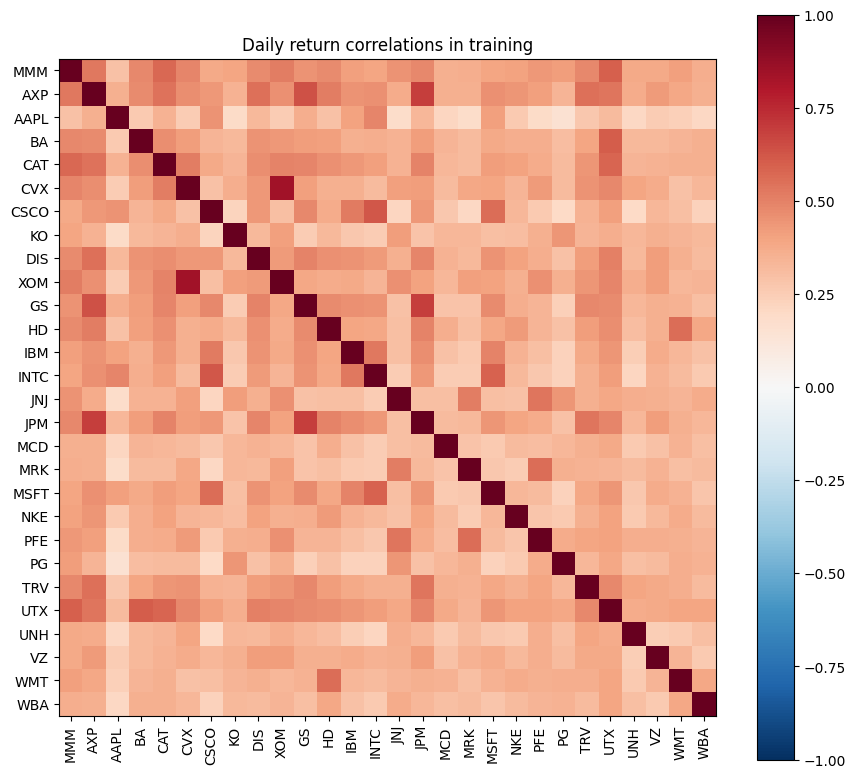

In [2]:
print(train.describe().T[["mean", "std", "min", "max"]].round(4).to_string())
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(train.corr(), vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(tickers)), tickers, rotation=90)
ax.set_yticks(range(len(tickers)), tickers)
ax.set_title("Daily return correlations in training")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## Construct eigen-portfolios

Fit PCA to standardized training returns. Each component supplies a candidate set of weights. Divide by the sum of its loadings so weights sum to one. Negative weights represent short positions. Components with near-zero sums are excluded.

Variance explained by first 10 components: 71.27%


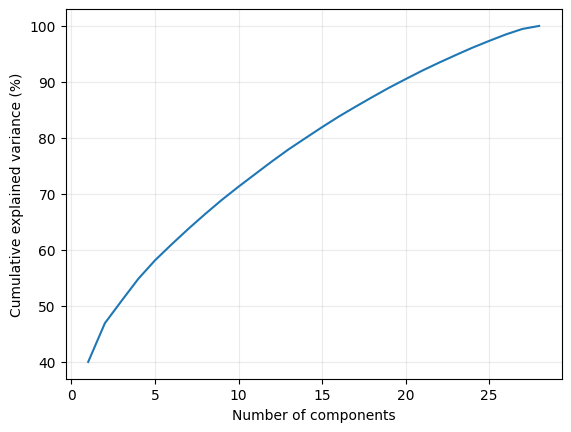

In [3]:
scaler = StandardScaler().fit(train)
pca = PCA(svd_solver="full").fit(scaler.transform(train))
loadings = pd.DataFrame(pca.components_, columns=tickers,
                        index=[f"PC{i+1}" for i in range(len(tickers))])
sums = loadings.sum(axis=1)
weights = loadings.loc[sums.abs() > 1e-8].div(sums[sums.abs() > 1e-8], axis=0)
assert np.allclose(weights.sum(axis=1), 1)
print("Variance explained by first 10 components:", f"{pca.explained_variance_ratio_[:10].sum():.2%}")
plt.plot(np.arange(1, len(tickers)+1), pca.explained_variance_ratio_.cumsum()*100)
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance (%)")
plt.grid(alpha=0.25)
plt.show()

## Select on training data and evaluate on later dates

Rank candidates by annualized Sharpe ratio, assuming a zero risk-free rate and 252 trading days per year. Exclude candidates that lose all capital on any training day. The benchmark allocates the same weight to each eligible ticker. Both portfolios rebalance daily.

Selected on training data: PC1
              Annualized return  Annualized volatility  Sharpe
PC1                      0.1217                 0.1343  0.9228
Equal weight             0.1233                 0.1328  0.9421
Gross exposure: 1.0


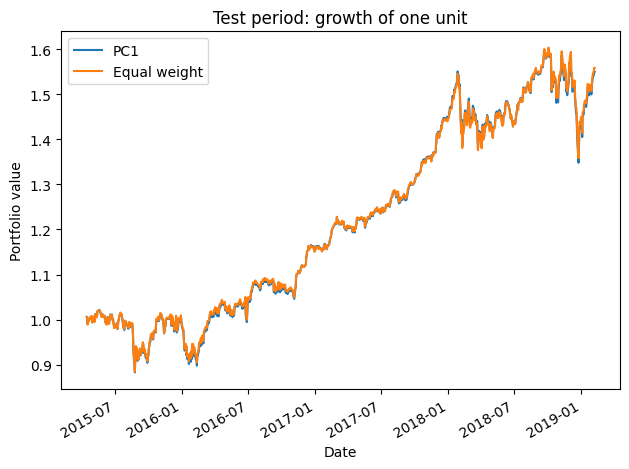

In [4]:
def performance(daily):
    volatility = daily.std() * np.sqrt(252)
    annual_return = np.expm1(np.log1p(daily).mean() * 252) if daily.min() > -1 else np.nan
    return pd.Series({"Annualized return": annual_return, "Annualized volatility": volatility,
                      "Sharpe": daily.mean() * 252 / volatility if volatility > 0 else np.nan})

training_paths = train.dot(weights.T)
viable = training_paths.columns[(training_paths > -1).all()]
ranking = training_paths[viable].apply(performance).T.sort_values("Sharpe", ascending=False)
selected = ranking.index[0]
print("Selected on training data:", selected)
held_out = pd.DataFrame({selected: test.dot(weights.loc[selected]), "Equal weight": test.mean(axis=1)})
assert (held_out > -1).all().all()
results = held_out.apply(performance).T
print(results.round(4).to_string())
print("Gross exposure:", round(weights.loc[selected].abs().sum(), 3))
(1 + held_out).cumprod().plot(title="Test period: growth of one unit", ylabel="Portfolio value")
plt.tight_layout()
plt.show()